# Informe ejecutivo – Predicción de demanda M5 (Walmart, California)

**Materia:** Machine learning y Procesamiento de datos · **Tecnicatura:** Data Science and AI
**Autora:** Taisiia Bogatyreva · **Fecha:** 13.11.2026


## 0. Configuración del entorno
`Настройка окружения`
### 0.1 Importaciones y rutas de archivos
`Импорты и пути к файлам`

Se importan las librerías necesarias y se definen las rutas **relativas** a la raíz del proyecto (el notebook está en `notebooks/`, por lo que los datos están en `../data/raw`).


In [1]:
from pathlib import Path
import gc

import numpy as np
import pandas as pd

DATA_DIR = Path("..") / "data" / "raw"
CALENDAR_PATH = DATA_DIR / "calendar.csv"
SALES_PATH = DATA_DIR / "sales_train_validation.csv"
PRICES_PATH = DATA_DIR / "sell_prices.csv"

# Verificación: los tres archivos deben existir
for ruta in [CALENDAR_PATH, SALES_PATH, PRICES_PATH]:
    print(f"{ruta} -> existe: {ruta.exists()}")

../data/raw/calendar.csv -> existe: True
../data/raw/sales_train_validation.csv -> existe: True
../data/raw/sell_prices.csv -> existe: True


# 1. Exploración y Procesamiento de Datos
`Исследование и обработка данных`

## 1.1 Carga e inspección de las tres fuentes
`Загрузка и осмотр трёх источников`
### 1.1.1 Lectura de los archivos
`Чтение файлов`

Se leen `calendar`, `sales_train_validation` y `sell_prices` y se guardan en un diccionario para inspeccionarlos con un único bucle.

In [2]:
calendar = pd.read_csv(CALENDAR_PATH)
sales = pd.read_csv(SALES_PATH)
prices = pd.read_csv(PRICES_PATH)

tablas = {
    "calendar": calendar,
    "sales_train_validation": sales,
    "sell_prices": prices,
}

### 1.1.2 Dimensiones, primeras filas y uso de memoria
Размеры, первые строки и использование памяти

Para cada tabla se muestra `shape`, `head()` (solo las primeras 10 columnas, para no exponer datos crudos) e `info()` con memoria real (`memory_usage="deep"`).

In [3]:
for nombre, df in tablas.items():
    print("=" * 70)
    print(f"TABLA: {nombre}")
    print(f"shape: {df.shape}")
    display(df.iloc[:, :10].head())
    # Para sales (~1900 columnas) se evita listar todas las columnas
    df.info(verbose=(df.shape[1] < 50), memory_usage="deep")

TABLA: calendar
shape: (1969, 14)


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   date          1969 non-null   str  
 1   wm_yr_wk      1969 non-null   int64
 2   weekday       1969 non-null   str  
 3   wday          1969 non-null   int64
 4   month         1969 non-null   int64
 5   year          1969 non-null   int64
 6   d             1969 non-null   str  
 7   event_name_1  162 non-null    str  
 8   event_type_1  162 non-null    str  
 9   event_name_2  5 non-null      str  
 10  event_type_2  5 non-null      str  
 11  snap_CA       1969 non-null   int64
 12  snap_TX       1969 non-null   int64
 13  snap_WI       1969 non-null   int64
dtypes: int64(7), str(7)
memory usage: 263.1 KB
TABLA: sales_train_validation
shape: (30490, 1919)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1919 entries, id to d_1913
dtypes: int64(1913), str(6)
memory usage: 448.2 MB
TABLA: sell_prices
shape: (6841121, 4)


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


<class 'pandas.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    str    
 1   item_id     str    
 2   wm_yr_wk    int64  
 3   sell_price  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 318.1 MB


### 1.1.3 Memoria total antes de la optimización
`Общая память до оптимизации`

Se calcula la memoria de cada tabla (en MB) y el total.

In [4]:
def mem_mb(df):
    """Memoria real que ocupa un DataFrame, en MB."""
    return df.memory_usage(deep=True).sum() / 1024**2

mem_antes = {nombre: mem_mb(df) for nombre, df in tablas.items()}
for nombre, valor in mem_antes.items():
    print(f"{nombre:25s} {valor:10.1f} MB")
print(f"{'TOTAL':25s} {sum(mem_antes.values()):10.1f} MB")

calendar                         0.3 MB
sales_train_validation         448.2 MB
sell_prices                    318.1 MB
TOTAL                          766.6 MB


### 1.1.4 Respuestas a las preguntas de la inspección
`Ответы на вопросы по осмотру`

1. **`sales_train_validation`**: tiene **30 490 filas y 1 919 columnas**. Cada fila es una **serie temporal independiente**: la combinación de un producto (`item_id`) en una tienda (`store_id`); 30 490 = 3 049 productos × 10 tiendas. Las primeras 6 columnas (`id`, `item_id`, `dept_id`, `cat_id`, `store_id`, `state_id`) son identificadores y las **1 913 columnas `d_1 … d_1913`** son los días de la historia: el valor de cada celda es la **cantidad de unidades vendidas** de ese producto en esa tienda en ese día. Es un formato *wide* (ancho): el tiempo está en las columnas.

2. **Claves de unión**:
   - `calendar` ↔ ventas: la columna **`d`** (en `calendar` contiene `d_1, d_2, …`, igual que los nombres de columnas de ventas; tras el `melt` se une por `d`).
   - `calendar` ↔ `sell_prices`: la columna **`wm_yr_wk`** (identificador de semana). El precio está definido por **tienda + producto + semana**, no por día, por eso se une a través de la semana.

3. **Memoria total** de las tres tablas (antes de optimizar): `calendar` 0.3 MB + `sales_train_validation` 448.2 MB + `sell_prices` 318.1 MB = **766.6 MB**.

## 1.2 Optimización de memoria (downcasting y `category`)

`Оптимизация памяти (понижение разрядности и category)`

> Nota: el downcasting se aplica **antes** del `melt` (1.3) de forma deliberada: la tabla ancha es pequeña, y reducir tipos antes del despivotado evita que la tabla larga (> 50 millones de filas) ocupe memoria innecesaria.

### 1.2.1 Función de reducción de tipos de datos (downcasting)
`Функция понижения разрядности типов`

La función recorre las columnas numéricas y asigna el tipo más pequeño que contenga todos los valores:
- **Enteros:** `int8 → int16 → int32 → int64`, comparando mínimo y máximo con `np.iinfo`.
- **Flotantes:** `float64 → float32`.
- Las columnas de texto no se tocan (se tratan en 1.2.3).
Al final se imprime la memoria antes y después.

In [5]:
def reducir_memoria(df, nombre=""):
    """Reduce los tipos numéricos de df al mínimo posible y reporta el ahorro."""
    antes = mem_mb(df)

    for col in df.columns:
        serie = df[col]

        if pd.api.types.is_integer_dtype(serie):
            c_min, c_max = serie.min(), serie.max()
            for tipo in (np.int8, np.int16, np.int32, np.int64):
                limites = np.iinfo(tipo)
                if limites.min <= c_min and c_max <= limites.max:
                    df[col] = serie.astype(tipo)
                    break

        elif pd.api.types.is_float_dtype(serie):
            df[col] = serie.astype(np.float32)

        # object / category / datetime: se dejan igual

    despues = mem_mb(df)
    print(f"{nombre:25s} {antes:9.1f} MB -> {despues:9.1f} MB "
          f"({100 * (1 - despues / antes):.0f}% menos)")
    return df

### 1.2.2 Aplicación del downcasting a las tres tablas
`Применение downcasting к трём таблицам`

Se aplica la función a cada tabla y se compara la memoria antes y después.

In [6]:
for nombre, df in tablas.items():
    tablas[nombre] = reducir_memoria(df, nombre)

calendar = tablas["calendar"]
sales = tablas["sales_train_validation"]
prices = tablas["sell_prices"]

print("\nTOTAL después del downcasting:",
      f"{sum(mem_mb(df) for df in tablas.values()):.1f} MB")

calendar                        0.3 MB ->       0.2 MB (34% menos)
sales_train_validation        448.2 MB ->      96.3 MB (79% menos)
sell_prices                   318.1 MB ->     252.9 MB (21% menos)

TOTAL después del downcasting: 349.4 MB


### 1.2.3 Conversión de identificadores de texto a `category`
`Перевод текстовых id в category`

El tipo `category` guarda cada texto único una sola vez y representa las filas con códigos enteros. Solo conviene con **pocos valores únicos y muchas filas**: se calcula `únicos / filas` y se convierte únicamente si es menor a 0.5.

In [7]:
def a_categoria(df, columnas, umbral=0.5):
    """Convierte a 'category' las columnas con pocos valores únicos."""
    antes = mem_mb(df)
    for col in columnas:
        proporcion = df[col].nunique() / len(df)
        if proporcion < umbral:
            df[col] = df[col].astype("category")
            print(f"  {col:15s} proporción únicos/filas = {proporcion:.5f} -> category")
        else:
            print(f"  {col:15s} proporción únicos/filas = {proporcion:.5f} -> se deja igual")
    print(f"  Memoria: {antes:.1f} MB -> {mem_mb(df):.1f} MB\n")
    return df

print("sales_train_validation")
sales = a_categoria(
    sales, ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
)

print("calendar")
calendar = a_categoria(
    calendar,
    ["d", "weekday", "event_name_1", "event_type_1", "event_name_2", "event_type_2"],
)
calendar["date"] = pd.to_datetime(calendar["date"])  # fecha como datetime

print("sell_prices")
prices = a_categoria(prices, ["store_id", "item_id"])

gc.collect()

sales_train_validation
  id              proporción únicos/filas = 1.00000 -> se deja igual
  item_id         proporción únicos/filas = 0.10000 -> category
  dept_id         proporción únicos/filas = 0.00023 -> category
  cat_id          proporción únicos/filas = 0.00010 -> category
  store_id        proporción únicos/filas = 0.00033 -> category
  state_id        proporción únicos/filas = 0.00010 -> category
  Memoria: 96.3 MB -> 94.4 MB

calendar
  d               proporción únicos/filas = 1.00000 -> se deja igual
  weekday         proporción únicos/filas = 0.00356 -> category
  event_name_1    proporción únicos/filas = 0.01524 -> category
  event_type_1    proporción únicos/filas = 0.00203 -> category
  event_name_2    proporción únicos/filas = 0.00203 -> category
  event_type_2    proporción únicos/filas = 0.00102 -> category
  Memoria: 0.2 MB -> 0.1 MB

sell_prices
  store_id        proporción únicos/filas = 0.00000 -> category
  item_id         proporción únicos/filas = 0.00045 ->

0

**Resultado:** la memoria total se redujo de 766.6 MB a aproximadamente 153 MB (≈ 80 % menos). El downcasting fue decisivo en `sales_train_validation` (−79 %) y la conversión a `category` en `sell_prices` (252.9 → 58.8 MB).

## 1.3 Integración de fuentes y transformación a formato largo (melt)
`Объединение источников и переход в длинный формат`

Dado que el formato largo completo supera los 50 millones de filas, se aplica la estrategia de reducción sugerida en la consigna: se trabaja **solo con el estado de California (CA)** y con el historial **desde `d_1500` hasta `d_1913`** (414 días, ≈ 13,6 meses). Esta ventana incluye los últimos 28 días (`d_1886 … d_1913`) que se usarán como validación en la fase 3.

### 1.3.1 Filtrado por estado y ventana temporal
`Фильтр по штату и временному окну`

Se seleccionan las series de CA y solo las columnas `d_1500 … d_1913`. Se eliminan las categorías sin uso (`remove_unused_categories`) para que, al unir con `sell_prices`, los tipos `category` de ambas tablas coincidan.


In [8]:
ESTADO = "CA"
PRIMER_DIA = 1500
ULTIMO_DIA = 1913

cols_id = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
cols_d = [f"d_{i}" for i in range(PRIMER_DIA, ULTIMO_DIA + 1)]

# 'id' pasa a category: en formato largo se repetirá 414 veces
sales["id"] = sales["id"].astype("category")

sales_ca = sales.loc[sales["state_id"] == ESTADO, cols_id + cols_d].copy()

# Quitar categorías de otros estados que ya no aparecen
for col in cols_id:
    sales_ca[col] = sales_ca[col].cat.remove_unused_categories()

print(f"Series producto-tienda en {ESTADO}: {len(sales_ca):,}")
print(f"Tiendas: {list(sales_ca['store_id'].cat.categories)}")
print(f"Días en la ventana: {len(cols_d)}")

Series producto-tienda en CA: 12,196
Tiendas: ['CA_1', 'CA_2', 'CA_3', 'CA_4']
Días en la ventana: 414


### 1.3.2 Despivotado de `wide` a `long` (`melt`)
`Переход из широкого формата в длинный`

`melt` convierte las 414 columnas de días en filas: cada fila pasa a ser una observación **(producto, tienda, día)** con su cantidad vendida. Se extrae el número de día (`d_1500` → `1500`) como entero para poder ordenar cronológicamente (ordenar el texto `d_1000` antes que `d_999` sería un error).



In [9]:
largo = sales_ca.melt(
    id_vars=cols_id,
    value_vars=cols_d,
    var_name="d",
    value_name="ventas",
)

# Número de día como entero pequeño (d_1500 -> 1500)
largo["d_num"] = largo["d"].str[2:].astype("int16")
largo = largo.drop(columns="d")

print(largo.shape)
print(largo.dtypes)

del sales_ca
gc.collect()

(5049144, 8)
id          category
item_id     category
dept_id     category
cat_id      category
store_id    category
state_id    category
ventas         int16
d_num          int16
dtype: object


0

### 1.3.3 Unión con `calendar`
`Объединение с calendar`

Se une `calendar` a la tabla larga mediante el número de día (`d_num`). Se conservan solo las columnas útiles y, dado que se trabaja únicamente con CA, solo la variable `snap_CA` (renombrada `snap`). El argumento `validate="many_to_one"` garantiza que cada día aparezca una sola vez en `calendar` y que la unión no duplique filas.


In [10]:
calendar["d_num"] = calendar["d"].str[2:].astype("int16")

cols_cal = ["d_num", "date", "wm_yr_wk", "wday", "month", "year",
            "event_name_1", "event_type_1", "event_name_2", "event_type_2",
            "snap_CA"]

cal_ca = (
    calendar.loc[calendar["d_num"].between(PRIMER_DIA, ULTIMO_DIA), cols_cal]
    .rename(columns={"snap_CA": "snap"})
)

filas_antes = len(largo)
largo = largo.merge(cal_ca, on="d_num", how="left", validate="many_to_one")
assert len(largo) == filas_antes, "La unión con calendar cambió el número de filas"

print(largo.shape)

(5049144, 18)


### 1.3.4 Unión con `sell_prices` y tratamiento de ceros
`Объединение с sell_prices и обработка нулей`

Los precios se unen por **tienda + producto + semana** (`store_id`, `item_id`, `wm_yr_wk`). Si un producto no tiene precio en una semana, significa que **aún no estaba a la venta** en esa tienda: ese cero de ventas **no es falta de demanda**. Para distinguirlos se crea la variable binaria `en_venta` (`True` si hay precio). Antes de unir se igualan las categorías de las claves en ambas tablas para que `category` no se convierta en texto.

In [11]:
# 1) Solo precios de tiendas CA y de las semanas de nuestra ventana
semanas = cal_ca["wm_yr_wk"].unique()
cats = {col: largo[col].cat.categories for col in ["store_id", "item_id"]}

prices_ca = prices.loc[
    prices["store_id"].isin(cats["store_id"]) & prices["wm_yr_wk"].isin(semanas)
].copy()

# 2) Mismas categorías (mismo orden) en las claves de ambas tablas
for col, categorias in cats.items():
    prices_ca[col] = prices_ca[col].astype(pd.CategoricalDtype(categorias))
    assert prices_ca[col].notna().all(), f"Categorías no encontradas en {col}"

# 3) Unión
filas_antes = len(largo)
largo = largo.merge(
    prices_ca, on=["store_id", "item_id", "wm_yr_wk"],
    how="left", validate="many_to_one",
)
assert len(largo) == filas_antes

# 4) Indicador de producto a la venta
largo["en_venta"] = largo["sell_price"].notna()

sin_precio = ~largo["en_venta"]
print(f"Filas sin precio (producto aún no a la venta): {sin_precio.mean():.1%}")
print(f"Unidades vendidas en filas sin precio: {largo.loc[sin_precio, 'ventas'].sum()}")

Filas sin precio (producto aún no a la venta): 0.8%
Unidades vendidas en filas sin precio: 0


### 1.3.5 Liberación de memoria y verificación
`Освобождение памяти и проверка`

Se eliminan las tablas intermedias y se invoca el recolector de basura (`gc.collect()`), tal como recomienda la consigna. Luego se vuelve a aplicar el downcasting y se verifica la forma, los tipos, la memoria y los valores nulos de la tabla larga.

In [12]:
# 'tablas' guarda referencias a los DataFrames originales: hay que borrarla también
del sales, prices, prices_ca, cal_ca, tablas
gc.collect()

largo = reducir_memoria(largo, "largo")

filas_esperadas = 12_196 * len(cols_d)
print(f"\nFilas: {len(largo):,} (esperadas: {filas_esperadas:,})")
print(f"Memoria: {mem_mb(largo):.1f} MB\n")
print(largo.dtypes, "\n")
print("Valores nulos por columna:")
print(largo.isna().sum())
display(largo.head(3))

largo                         173.8 MB ->     173.8 MB (0% menos)

Filas: 5,049,144 (esperadas: 5,049,144)
Memoria: 173.8 MB

id                    category
item_id               category
dept_id               category
cat_id                category
store_id              category
state_id              category
ventas                   int16
d_num                    int16
date            datetime64[us]
wm_yr_wk                 int16
wday                      int8
month                     int8
year                     int16
event_name_1          category
event_type_1          category
event_name_2          category
event_type_2          category
snap                      int8
sell_price             float32
en_venta                  bool
dtype: object 

Valores nulos por columna:
id                    0
item_id               0
dept_id               0
cat_id                0
store_id              0
state_id              0
ventas                0
d_num                 0
date               

,id,item_id,dept_id,cat_id,store_id,state_id,ventas,d_num,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap,sell_price,en_venta
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,1500,2015-03-08,11506,2,3,2015,NaN,NaN,NaN,NaN,1,8.26,True
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,1500,2015-03-08,11506,2,3,2015,NaN,NaN,NaN,NaN,1,3.97,True
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,1500,2015-03-08,11506,2,3,2015,NaN,NaN,NaN,NaN,1,2.97,True


**Resultado:** 40 279 filas (0,8 %) no tienen precio y en todas ellas las ventas son 0. Esto confirma que corresponden a productos **aún no a la venta** y no a "falta de demanda".

## 1.4 Análisis Exploratorio de Datos (EDA)
`Разведочный анализ данных`

Se analizan los patrones de **estacionalidad** (días de la semana, fin de mes), las **tendencias por categoría**, el **comportamiento de precios** y la **demanda intermitente**. Se usan 5 gráficos; las conclusiones se resumen en 1.4.6.


### 1.4.1 Calidad de los datos y tratamiento de ceros
`Качество данных и обработка нулей`

Se verifica si las filas sin precio (producto aún no a la venta) se concentran **al inicio** de cada serie. Si es así, pueden excluirse del entrenamiento sin romper la continuidad temporal de los lags. Luego se calcula la proporción de ceros **reales** (producto a la venta pero sin ventas).

In [13]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

sin_precio = largo.loc[~largo["en_venta"]]
con_precio = largo.loc[largo["en_venta"]]

# Último día sin precio vs primer día con precio, por serie
ultimo_sin = sin_precio.groupby("id", observed=True)["d_num"].max()
primer_con = con_precio.groupby("id", observed=True)["d_num"].min()
al_inicio = (ultimo_sin < primer_con.reindex(ultimo_sin.index)).mean()

print(f"Series con algún día sin precio: {len(ultimo_sin):,}")
print(f"De ellas, con todos los días sin precio al INICIO de la serie: {al_inicio:.1%}")

ceros_reales = (con_precio["ventas"] == 0).mean()
print(f"Ceros entre filas a la venta (ceros 'reales'): {ceros_reales:.1%}")

Series con algún día sin precio: 398
De ellas, con todos los días sin precio al INICIO de la serie: 100.0%
Ceros entre filas a la venta (ceros 'reales'): 57.0%


### 1.4.2 Estacionalidad semanal y de fin de mes
`Недельная сезонность и конец месяца`

Se calcula la venta media por serie y día para cada día de la semana y para cada día del mes, y se compara también el efecto de los días SNAP (subsidio alimentario de CA). Solo se usan filas con el producto a la venta.

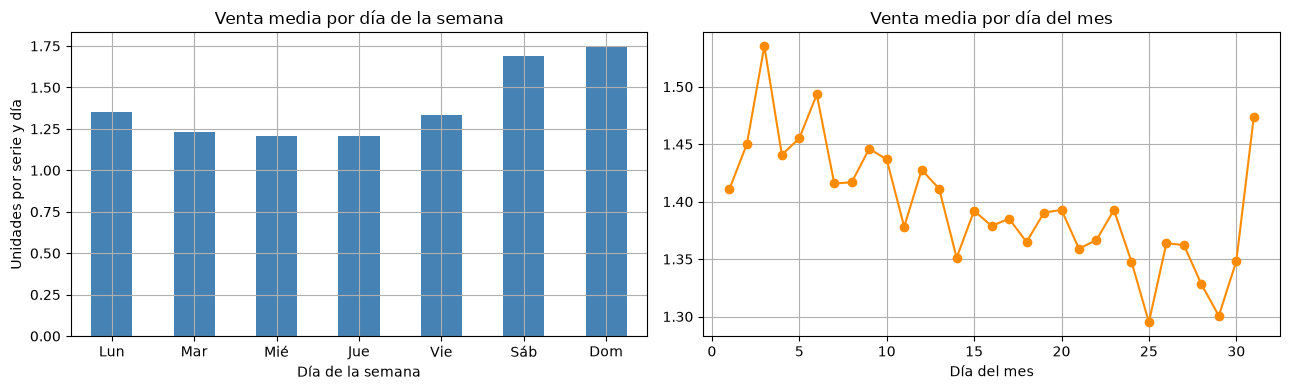

Venta media según día SNAP (0 = no, 1 = sí):
snap
0    1.371
1    1.450
Name: ventas, dtype: float64
date
1     1.0
2     1.0
3     1.0
4     1.0
5     1.0
6     1.0
7     1.0
8     1.0
9     1.0
10    1.0
11    0.0
12    0.0
13    0.0
14    0.0
15    0.0
16    0.0
17    0.0
18    0.0
19    0.0
20    0.0
21    0.0
22    0.0
23    0.0
24    0.0
25    0.0
26    0.0
27    0.0
28    0.0
29    0.0
30    0.0
31    0.0


In [14]:
# En M5, wday=1 es sábado
dias = {1: "Sáb", 2: "Dom", 3: "Lun", 4: "Mar", 5: "Mié", 6: "Jue", 7: "Vie"}
orden = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

por_semana = con_precio.groupby("wday", observed=True)["ventas"].mean()
por_semana.index = por_semana.index.map(dias)
por_semana = por_semana.reindex(orden)

por_dia_mes = con_precio.groupby(con_precio["date"].dt.day)["ventas"].mean()
efecto_snap = con_precio.groupby("snap", observed=True)["ventas"].mean()

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
por_semana.plot(kind="bar", ax=ejes[0], color="steelblue", rot=0)
ejes[0].set_xlabel("Día de la semana")
ejes[0].set_title("Venta media por día de la semana")
ejes[0].set_ylabel("Unidades por serie y día")

por_dia_mes.plot(marker="o", ax=ejes[1], color="darkorange")
ejes[1].set_title("Venta media por día del mes")
ejes[1].set_xlabel("Día del mes")
plt.tight_layout()
plt.show()

print("Venta media según día SNAP (0 = no, 1 = sí):")
print(efecto_snap.round(3))

print(calendar.groupby(calendar["date"].dt.day)["snap_CA"].mean().round(2).to_string())

### 1.4.3 Tendencia por categoría de producto
`Тренд по категориям товаров`

Se grafican las ventas diarias totales de CA por categoría (`FOODS`, `HOUSEHOLD`, `HOBBIES`) con una media móvil de 28 días para suavizar la estacionalidad semanal y destacar la tendencia.

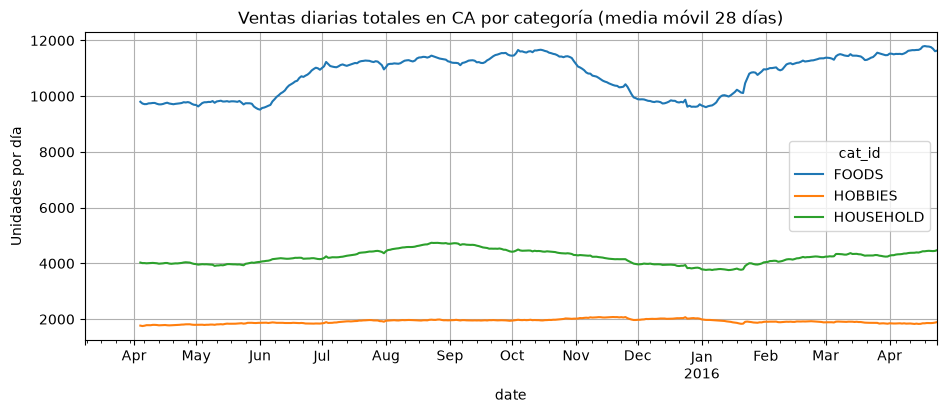

Participación de cada categoría en las unidades vendidas:
cat_id
FOODS        0.637
HOBBIES      0.113
HOUSEHOLD    0.250
dtype: float64


In [15]:
ventas_cat = (
    con_precio.groupby(["date", "cat_id"], observed=True)["ventas"]
    .sum()
    .unstack("cat_id")
)

ax = ventas_cat.rolling(28).mean().plot(figsize=(11, 4))
ax.set_title("Ventas diarias totales en CA por categoría (media móvil 28 días)")
ax.set_ylabel("Unidades por día")
plt.show()

print("Participación de cada categoría en las unidades vendidas:")
print((ventas_cat.sum() / ventas_cat.sum().sum()).round(3))

### 1.4.4 Comportamiento de los precios
`Поведение цен`

Se analiza el precio medio semanal por categoría y la frecuencia con la que cambia el precio de un mismo producto de una semana a otra.

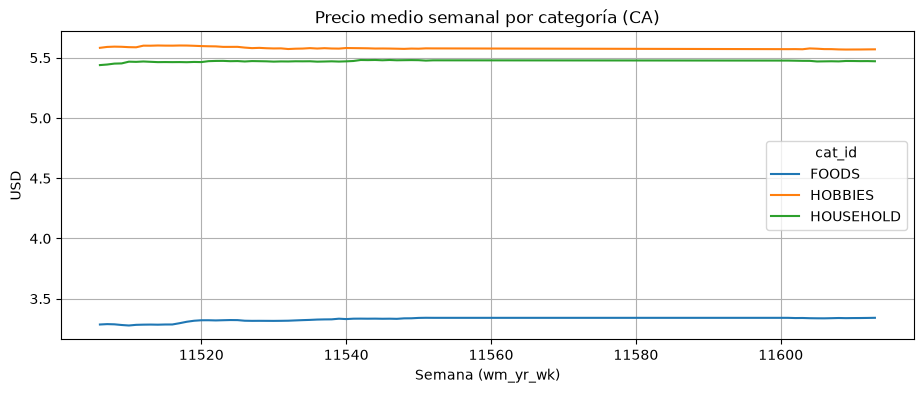

Semanas con cambio de precio: 0.9%


In [16]:
precio_cat = (
    con_precio.groupby(["wm_yr_wk", "cat_id"], observed=True)["sell_price"]
    .mean()
    .unstack("cat_id")
)

ax = precio_cat.plot(figsize=(11, 4))
ax.set_title("Precio medio semanal por categoría (CA)")
ax.set_xlabel("Semana (wm_yr_wk)")
ax.set_ylabel("USD")
plt.show()

# ¿Con qué frecuencia cambia el precio de una semana a la siguiente?
precio_semanal = (
    con_precio.drop_duplicates(["id", "wm_yr_wk"])
    .sort_values(["id", "wm_yr_wk"])
)
cambio = precio_semanal.groupby("id", observed=True)["sell_price"].diff()
print(f"Semanas con cambio de precio: {(cambio.dropna() != 0).mean():.1%}")

### 1.4.5 Demanda intermitente
`Прерывистый спрос`

Se calcula, para cada serie, el porcentaje de días a la venta con ventas iguales a 0. Una serie con muchos ceros es de demanda **intermitente**, difícil de pronosticar con métodos clásicos.

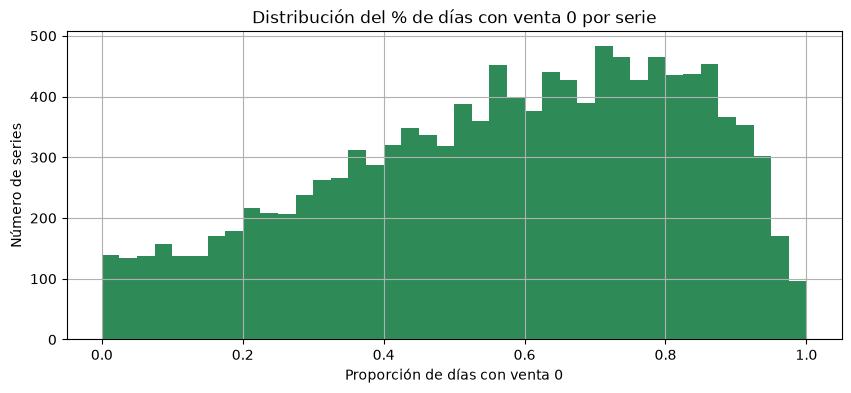

Series con más de 50 % de ceros: 62.8%
Series con más de 80 % de ceros: 21.4%


In [17]:
pct_ceros = (con_precio["ventas"] == 0).groupby(con_precio["id"], observed=True).mean()

ax = pct_ceros.plot(kind="hist", bins=40, figsize=(10, 4), color="seagreen")
ax.set_title("Distribución del % de días con venta 0 por serie")
ax.set_xlabel("Proporción de días con venta 0")
ax.set_ylabel("Número de series")
plt.show()

print(f"Series con más de 50 % de ceros: {(pct_ceros > 0.5).mean():.1%}")
print(f"Series con más de 80 % de ceros: {(pct_ceros > 0.8).mean():.1%}")

### 1.4.6 Conclusiones del EDA
`Выводы EDA`

1. **Ceros y precios:** 398 series (3,3 %) tienen días sin precio y en el 100 % de ellas esos días están al **inicio** de la serie; en esas filas las ventas son 0 (producto aún no a la venta). Entre las filas con producto a la venta, el **57,0 %** de los días tiene venta 0 (ceros "reales").
2. **Estacionalidad semanal:** sábado (≈ 1,69) y domingo (≈ 1,75) venden un 40-45 % más que martes-jueves (≈ 1,21-1,23); lunes y viernes son intermedios.
3. **Fin de mes y SNAP:** la venta media es mayor en los primeros días del mes (máximo ≈ 1,53 el día 3) y baja a ≈ 1,30-1,35 en la segunda quincena. En CA los días SNAP son **siempre los días 1 a 10 de cada mes** (verificado en `calendar`), y en ellos la venta media es un 5,8 % mayor (1,450 vs 1,371). *Limitación:* como SNAP coincide exactamente con los días 1-10, **no es posible separar el efecto SNAP del efecto "inicio de mes"**; ambos se interpretan conjuntamente. El mínimo del día 25 probablemente refleja la Navidad (una sola observación en la ventana).
4. **Tendencia por categoría:** FOODS concentra el 63,7 % de las unidades, HOUSEHOLD el 25,0 % y HOBBIES el 11,3 %. FOODS y HOUSEHOLD muestran estacionalidad anual (máximo en verano-otoño, caída en diciembre-enero) y crecimiento entre abril de 2015 y abril de 2016; HOBBIES es casi plana. Con solo 414 días no es posible separar tendencia de estacionalidad anual.
5. **Precios:** son muy estables (solo el 0,9 % de las semanas-serie cambia de precio). Precio medio: FOODS ≈ 3,3 USD, HOUSEHOLD ≈ 5,5 USD, HOBBIES ≈ 5,6 USD. Se espera que el nivel de precio y el precio relativo aporten más información que la variación temporal.
6. **Demanda intermitente:** el 62,8 % de las series tiene más de 50 % de días con venta 0 y el 21,4 % más de 80 %. Esto implica que el MAE favorece predicciones cercanas a cero, por lo que se reportarán RMSE y MAE conjuntamente.

**Decisión:** se **excluyen las 40 279 filas sin precio** (0,8 %): son ceros estructurales que no representan demanda, están al inicio de cada serie y su eliminación no rompe la continuidad temporal de los lags.

**Limitación:** la ventana de 414 días contiene cada evento de calendario solo 1-2 veces, por lo que el análisis del impacto de eventos (4.2) será indicativo, no concluyente.

In [18]:
n_antes = len(largo)
largo = largo.loc[largo["en_venta"]].drop(columns="en_venta").reset_index(drop=True)
print(f"Filas eliminadas: {n_antes - len(largo):,} ({1 - len(largo) / n_antes:.1%})")
print(f"Filas restantes: {len(largo):,}")

# Liberar las tablas auxiliares del EDA
del sin_precio, con_precio, precio_semanal, cambio
_ = gc.collect()

Filas eliminadas: 40,279 (0.8%)
Filas restantes: 5,008,865


# 2. Ingeniería de Características (Feature Engineering)
`Инженерия признаков`

## 2.1 Variables Temporales y Calendario
`Временные и календарные признаки`

Se construyen variables a partir del calendario. Por diseño, se descartan `year` y `d_num`: los árboles de decisión no pueden extrapolar valores fuera del rango visto en entrenamiento, y estas variables permitirían al modelo "memorizar el momento" en lugar de aprender patrones.

### 2.1.1 Variables derivadas de la fecha
Se crean el día de la semana (0 = lunes), el día del mes, los días que faltan para fin de mes y un indicador de fin de semana, según los patrones observados en 1.4.2.

In [19]:
fecha = largo["date"].dt

largo["dia_semana"] = fecha.dayofweek.astype("int8")          # 0 = lunes ... 6 = domingo
largo["dia_mes"] = fecha.day.astype("int8")
largo["dias_hasta_fin_mes"] = (fecha.days_in_month - fecha.day).astype("int8")
largo["fin_de_semana"] = (largo["dia_semana"] >= 5).astype("int8")

# wday (sáb = 1) es redundante con dia_semana; year no se usará como variable
largo = largo.drop(columns=["wday", "year"])

print(largo[["date", "dia_semana", "dia_mes", "dias_hasta_fin_mes", "fin_de_semana"]]
      .drop_duplicates("date").head(8).to_string(index=False))

      date  dia_semana  dia_mes  dias_hasta_fin_mes  fin_de_semana
2015-03-08           6        8                  23              1
2015-03-09           0        9                  22              0
2015-03-10           1       10                  21              0
2015-03-11           2       11                  20              0
2015-03-12           3       12                  19              0
2015-03-13           4       13                  18              0
2015-03-14           5       14                  17              1
2015-03-15           6       15                  16              1


### 2.1.2 Eventos y SNAP
Se crea un indicador `tiene_evento` (1 si el día tiene algún evento) y se completa el tipo de evento con la categoría "Ninguno". La variable `snap` (días de subsidio alimentario en CA) ya fue incorporada en 1.3.3. `event_name_1/2` se conservan solo para el análisis de impacto (4.2): con 30 nombres de evento y 1-2 apariciones cada uno, usarlos como variable del modelo provocaría sobreajuste.

In [20]:
largo["tiene_evento"] = (
    largo["event_name_1"].notna() | largo["event_name_2"].notna()
).astype("int8")

largo["event_type_1"] = largo["event_type_1"].cat.add_categories("Ninguno").fillna("Ninguno")

print(f"Proporción de filas con evento: {largo['tiene_evento'].mean():.1%}")
print(largo["event_type_1"].value_counts())
print(f"\nMemoria: {mem_mb(largo):.1f} MB")

Proporción de filas con evento: 7.7%
event_type_1
Ninguno      4621717
National      121505
Religious     121014
Cultural      108268
Sporting       36361
Name: count, dtype: int64

Memoria: 177.5 MB


## 2.2 Variables de Series Temporales (Lags y Ventanas Móviles)
`Признаки временных рядов (лаги и скользящие окна)`

Se predice un bloque de **28 días**; por lo tanto, para la fila del día *t* solo se pueden usar ventas **hasta el día t-28** (estrategia directa). Todas las variables de esta sección respetan esa regla. Los valores nulos al inicio de cada serie (no hay historia suficiente) **no se imputan**: LightGBM los maneja de forma nativa, y rellenarlos con una media global sería fuga de datos.

### 2.2.1 Rezagos (lags) alineados al horizonte
`Лаги, согласованные с горизонтом`

Se ordena la tabla por serie y día, y se calculan los lags 28, 29, 35 y 42 **dentro de cada serie** (`groupby("id")`).

In [21]:
largo = largo.sort_values(["id", "d_num"]).reset_index(drop=True)

grupo = largo.groupby("id", observed=True)["ventas"]

for k in (28, 29, 35, 42):
    largo[f"lag_{k}"] = grupo.shift(k).astype("float32")

print(largo[["id", "d_num", "ventas", "lag_28", "lag_29"]].head(3).to_string(index=False))
print(f"\nMemoria: {mem_mb(largo):.1f} MB")

                         id  d_num  ventas  lag_28  lag_29
FOODS_1_001_CA_1_validation   1500       1     NaN     NaN
FOODS_1_001_CA_1_validation   1501       0     NaN     NaN
FOODS_1_001_CA_1_validation   1502       1     NaN     NaN

Memoria: 253.9 MB


### 2.2.2 Medias y desviaciones móviles sobre `shift(28)`
`Скользящие среднее и std поверх shift(28)`

Primero se desplaza la serie 28 días y **después** se calculan la media y la desviación estándar móviles (ventanas de 7 y 28 días). Así, ninguna ventana contiene ventas posteriores al día t-28. Por restricción de tiempo se omiten las ventanas de 14 y 56 días.

In [22]:
largo["ventas_s28"] = grupo.shift(28)
grupo_s28 = largo.groupby("id", observed=True)["ventas_s28"]

for w in (7, 28):
    largo[f"media_{w}"] = grupo_s28.transform(lambda s: s.rolling(w).mean()).astype("float32")
    largo[f"std_{w}"] = grupo_s28.transform(lambda s: s.rolling(w).std()).astype("float32")

largo = largo.drop(columns="ventas_s28")
_ = gc.collect()

cols_rezago = ["lag_28", "lag_29", "lag_35", "lag_42", "media_7", "std_7", "media_28", "std_28"]
print(largo[cols_rezago].isna().mean().round(3))
print(f"\nMemoria: {mem_mb(largo):.1f} MB")

lag_28      0.068
lag_29      0.071
lag_35      0.085
lag_42      0.102
media_7     0.083
std_7       0.083
media_28    0.134
std_28      0.134
dtype: float64

Memoria: 330.3 MB


### 2.2.3 Verificación de ausencia de fuga de datos
`Проверка отсутствия утечки данных`

Se comprueba con aserciones que (1) los días de cada serie son consecutivos, de modo que desplazar *k* filas equivale a desplazar *k* días, y (2) los valores calculados coinciden con un cálculo manual usando únicamente ventas hasta t-28.

In [23]:
# 1) Días consecutivos dentro de cada serie
saltos = largo.groupby("id", observed=True)["d_num"].diff().dropna()
assert (saltos == 1).all(), "Hay huecos en alguna serie"

# 2) Comprobación manual en una serie
una = largo[largo["id"] == largo["id"].iloc[0]].reset_index(drop=True)
i = 100
assert una.loc[i, "lag_28"] == una.loc[i - 28, "ventas"]
manual = una.loc[i - 34 : i - 28, "ventas"].mean()      # 7 días: t-34 ... t-28
assert np.isclose(una.loc[i, "media_7"], manual)

print("OK: lags y ventanas usan solo información hasta t-28.")

OK: lags y ventanas usan solo información hasta t-28.


**Resultado:** las verificaciones pasaron: los días son consecutivos en todas las series y los valores de `lag_28` y `media_7` coinciden con el cálculo manual hasta t-28. No hay fuga de datos en las variables de rezago.

## 2.3 Variables Monetarias
`Ценовые признаки`

Se construyen tres tipos de variables de precio. A diferencia de las ventas, **el precio sí se conoce con antelación** (la tienda lo define y la tabla `sell_prices` incluye las semanas futuras), por lo que **no es necesario desplazarlo 28 días** y no genera fuga de datos. Según 1.4.4, los precios cambian poco (0,9 % de las semanas-serie), por lo que se espera que el nivel de precio y el precio relativo sean más informativos que las variaciones.


### 2.3.1 Precio relativo dentro del departamento
`Относительная цена внутри департамента`

Se divide el precio de cada producto por el precio medio de su departamento en la misma tienda y semana. Un valor mayor que 1 indica un producto más caro que el promedio de su departamento.

In [24]:
precio_medio_dept = largo.groupby(
    ["store_id", "dept_id", "wm_yr_wk"], observed=True
)["sell_price"].transform("mean")

largo["precio_rel_dept"] = (largo["sell_price"] / precio_medio_dept).astype("float32")

del precio_medio_dept
_ = gc.collect()

print(largo["precio_rel_dept"].describe().round(3))

count    5008865.000
mean           1.000
std            0.666
min            0.019
25%            0.576
50%            0.861
75%            1.285
max            6.554
Name: precio_rel_dept, dtype: float64


### 2.3.2 Variación porcentual del precio
`Процентное изменение цены`

Se calcula la variación porcentual del precio respecto a 1 semana (7 días) y 4 semanas (28 días) antes, dentro de cada serie.

In [25]:
grupo_precio = largo.groupby("id", observed=True)["sell_price"]

for dias, nombre in ((7, "1s"), (28, "4s")):
    precio_previo = grupo_precio.shift(dias)
    largo[f"cambio_precio_{nombre}"] = (largo["sell_price"] / precio_previo - 1).astype("float32")

del precio_previo
_ = gc.collect()

for col in ("cambio_precio_1s", "cambio_precio_4s"):
    print(f"{col}: filas con cambio ≠ 0: {(largo[col].dropna() != 0).mean():.1%}")

cambio_precio_1s: filas con cambio ≠ 0: 0.9%
cambio_precio_4s: filas con cambio ≠ 0: 3.2%


### 2.3.3 Descuentos
`Скидки`
Se mide el descuento como la caída del precio actual respecto al **precio máximo de las últimas 8 semanas (56 días)** de la misma serie, y se crea un indicador binario `en_descuento`.

In [26]:
precio_max_56 = grupo_precio.transform(lambda s: s.rolling(56, min_periods=1).max())

largo["descuento_pct"] = (1 - largo["sell_price"] / precio_max_56).astype("float32")
largo["en_descuento"] = (largo["descuento_pct"] > 0).astype("int8")

del precio_max_56
_ = gc.collect()

print(f"Filas en descuento: {largo['en_descuento'].mean():.1%}")
print(largo.loc[largo["en_descuento"] == 1, "descuento_pct"].describe().round(3))
print(f"\nMemoria: {mem_mb(largo):.1f} MB")

Filas en descuento: 2.3%
count    117026.000
mean          0.109
std           0.093
min           0.001
25%           0.041
50%           0.094
75%           0.140
max           0.983
Name: descuento_pct, dtype: float64

Memoria: 411.6 MB


**Resultado:** se crearon `precio_rel_dept`, `cambio_precio_1s`, `cambio_precio_4s`, `descuento_pct` y `en_descuento`. Solo el 0,9 % de las filas presenta un cambio de precio semanal, el 3,2 % un cambio a 4 semanas y el 2,3 % de las filas está en descuento (descuento medio del 10,9 % respecto al máximo de las últimas 8 semanas). Como el precio es conocido con antelación, estas variables no requieren desplazamiento de 28 días.

# 3. Modelado y Validación Temporal
`Моделирование и временная валидация`

## 3.1 Modelo base de referencia (baseline)
`Базовая модель (бейзлайн)`

Antes de usar ingeniería de características avanzada o modelos complejos se fija un **umbral mínimo de rendimiento** con métodos simples. Cualquier modelo posterior debe superarlo para justificar su complejidad.

### 3.1.1 Corte temporal entrenamiento / validación
`Временное разбиение на обучение и валидацию`

Se usa un único corte cronológico (*out-of-time*): **entrenamiento** `d_1500 … d_1885` y **validación** los últimos 28 días conocidos `d_1886 … d_1913`. La validación está estrictamente después del entrenamiento (ver 3.3).

In [27]:
ULTIMO_TRAIN = 1885
PRIMER_VAL = 1886
ULTIMO_VAL = 1913   # último día con ventas conocidas
HORIZONTE = ULTIMO_VAL - PRIMER_VAL + 1

assert largo["d_num"].max() == ULTIMO_VAL
assert HORIZONTE == 28

n_train = (largo["d_num"] <= ULTIMO_TRAIN).sum()
n_val = (largo["d_num"] >= PRIMER_VAL).sum()
print(f"Filas de entrenamiento: {n_train:,}")
print(f"Filas de validación:    {n_val:,}  (horizonte = {HORIZONTE} días)")

Filas de entrenamiento: 4,667,377
Filas de validación:    341,488  (horizonte = 28 días)


### 3.1.2 Baselines: ingenuo estacional, media móvil y cero
`Бейзлайны: сезонный наивный, скользящее среднее и ноль`

Se evalúan tres referencias, todas construidas **solo con ventas hasta `d_1885`**:
1. **Ingenuo estacional:** la venta de cada día se predice con la del mismo día de la semana en la última semana conocida.
2. **Media móvil de 28 días:** se predice un valor constante, igual a la media de los últimos 28 días de entrenamiento.
3. **Predicción cero:** referencia extrema que aprovecha la alta proporción de ceros (1.4.5).
Se reportan RMSE y MAE (la métrica WRMSSE no se calcula por restricción de tiempo).

In [28]:
def rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))

def mae(y, p):
    return float(np.mean(np.abs(y - p)))

val = largo.loc[largo["d_num"] >= PRIMER_VAL, ["id", "d_num", "ventas"]].copy()

# 1) Ingenuo estacional: mismo día de la semana en la última semana de entrenamiento
k = np.ceil((val["d_num"] - ULTIMO_TRAIN) / 7).astype(int)
val["d_ref"] = (val["d_num"] - 7 * k).astype("int16")

ref = (
    largo.loc[largo["d_num"].between(ULTIMO_TRAIN - 6, ULTIMO_TRAIN), ["id", "d_num", "ventas"]]
    .rename(columns={"d_num": "d_ref", "ventas": "pred_ingenuo"})
)
filas = len(val)
val = val.merge(ref, on=["id", "d_ref"], how="left")
assert len(val) == filas

# 2) Media móvil de 28 días (solo entrenamiento)
media28 = (
    largo.loc[largo["d_num"].between(ULTIMO_TRAIN - 27, ULTIMO_TRAIN)]
    .groupby("id", observed=True)["ventas"].mean()
    .rename("pred_media28").reset_index()
)
val = val.merge(media28, on="id", how="left")
assert len(val) == filas

# Series sin historia reciente (productos que empiezan a venderse en la validación)
sin_hist = val["pred_ingenuo"].isna().mean()
print(f"Filas de validación sin historia en la última semana: {sin_hist:.2%}")
val[["pred_ingenuo", "pred_media28"]] = val[["pred_ingenuo", "pred_media28"]].fillna(0)

# 3) Cero
val["pred_cero"] = 0.0

y = val["ventas"].to_numpy(dtype="float64")
resultados = {}
for col in ("pred_ingenuo", "pred_media28", "pred_cero"):
    p = val[col].to_numpy(dtype="float64")
    resultados[col] = {"RMSE": rmse(y, p), "MAE": mae(y, p)}

print(pd.DataFrame(resultados).T.round(4))

Filas de validación sin historia en la última semana: 0.00%
                RMSE     MAE
pred_ingenuo  2.8315  1.3244
pred_media28  2.2604  1.1070
pred_cero     3.8650  1.4764


**Resultado:** sobre los 28 días de validación (`d_1886 … d_1913`) el baseline ingenuo estacional obtiene RMSE = [..] y MAE = [..]; la media móvil de 28 días, RMSE = [..] y MAE = [..]; la predicción cero, RMSE = [..] y MAE = [..]. Estas cifras fijan el umbral que debe superar el modelo de la sección 3.2.

## 3.2 Modelo LightGBM
`Модель LightGBM`


### 3.2.1 Selección de variables
`Выбор признаков`

- **Categóricas:** `dept_id`, `cat_id`, `store_id`, `event_type_1`.
- **Numéricas:** calendario (`dia_semana`, `dia_mes`, `dias_hasta_fin_mes`, `fin_de_semana`, `month`, `snap`, `tiene_evento`), rezagos y ventanas (2.2) y precios (2.3).
- **Excluidas:** `id` y `item_id` (identificadores de alta cardinalidad: favorecen el sobreajuste; la información de cada serie ya llega por lags y medias), `state_id` (constante), `d_num` y `date` (el árbol no extrapola el tiempo), `wm_yr_wk` y `event_name_1/2` (solo se usan en el análisis 4.2).



In [29]:
import lightgbm as lgb

CATEGORICAS = ["dept_id", "cat_id", "store_id", "event_type_1"]
NUMERICAS = [
    "dia_semana", "dia_mes", "dias_hasta_fin_mes", "fin_de_semana", "month",
    "snap", "tiene_evento",
    "lag_28", "lag_29", "lag_35", "lag_42",
    "media_7", "std_7", "media_28", "std_28",
    "sell_price", "precio_rel_dept", "cambio_precio_1s", "cambio_precio_4s",
    "descuento_pct", "en_descuento",
]
FEATURES = CATEGORICAS + NUMERICAS

mask_train = largo["d_num"] <= ULTIMO_TRAIN
mask_val = largo["d_num"] >= PRIMER_VAL

X_train, y_train = largo.loc[mask_train, FEATURES], largo.loc[mask_train, "ventas"]
X_val, y_val = largo.loc[mask_val, FEATURES], largo.loc[mask_val, "ventas"]

print(f"Variables del modelo: {len(FEATURES)}")
print(f"Train: {X_train.shape}  |  Validación: {X_val.shape}")

Variables del modelo: 25
Train: (4667377, 25)  |  Validación: (341488, 25)


### 3.2.2 Entrenamiento
`Обучение`

Se usa la función objetivo **Tweedie** (`tweedie_variance_power = 1.1`): la variable objetivo son conteos no negativos con muchísimos ceros (57 % de ceros reales, ver 1.4.1), situación para la cual Tweedie es más adecuada que el error cuadrático. Se entrena un número fijo de 500 árboles; la validación solo se **monitorea** (no se usa para detener el entrenamiento ni para elegir parámetros), de modo que las métricas finales no están sesgadas por la selección del modelo.

In [30]:
params = {
    "objective": "tweedie",
    "tweedie_variance_power": 1.1,
    "metric": "rmse",
    "learning_rate": 0.05,
    "num_leaves": 63,
    "min_data_in_leaf": 100,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "seed": 42,
    "n_jobs": -1,
    "verbose": -1,
}

dtrain = lgb.Dataset(X_train, label=y_train, categorical_feature=CATEGORICAS)
dval = lgb.Dataset(X_val, label=y_val, reference=dtrain, categorical_feature=CATEGORICAS)

modelo = lgb.train(
    params, dtrain, num_boost_round=500,
    valid_sets=[dval], valid_names=["validacion"],
    callbacks=[lgb.log_evaluation(100)],
)

modelo.save_model("../models/lgbm_m5_ca.txt")

[100]	validacion's rmse: 2.19249
[200]	validacion's rmse: 2.17604
[300]	validacion's rmse: 2.16795
[400]	validacion's rmse: 2.1641
[500]	validacion's rmse: 2.16128


### 3.2.3 Predicción y comparación con el baseline
`Прогноз и сравнение с бейзлайном`

Se predicen los 28 días de validación y se comparan RMSE y MAE con los baselines de 3.1.2.

In [31]:
pred_lgbm = modelo.predict(X_val)

# Comprobación de alineación: las filas de 'val' (3.1.2) deben coincidir con X_val
assert np.array_equal(val["ventas"].to_numpy(), y_val.to_numpy())
val["pred_lgbm"] = pred_lgbm

y = val["ventas"].to_numpy(dtype="float64")
resultados["pred_lgbm"] = {"RMSE": rmse(y, pred_lgbm), "MAE": mae(y, pred_lgbm)}

tabla = pd.DataFrame(resultados).T.round(4)
mejor_base = tabla.loc[["pred_ingenuo", "pred_media28", "pred_cero"]].min()
print(tabla)
print("\nMejora de LightGBM vs. mejor baseline:")
print(f"  RMSE: {1 - tabla.loc['pred_lgbm', 'RMSE'] / mejor_base['RMSE']:.1%}")
print(f"  MAE:  {1 - tabla.loc['pred_lgbm', 'MAE'] / mejor_base['MAE']:.1%}")

                RMSE     MAE
pred_ingenuo  2.8315  1.3244
pred_media28  2.2604  1.1070
pred_cero     3.8650  1.4764
pred_lgbm     2.1613  1.1097

Mejora de LightGBM vs. mejor baseline:
  RMSE: 4.4%
  MAE:  -0.2%


**Resultado:** LightGBM obtiene RMSE = 2,1613 y MAE = 1,1097 en la validación, frente a RMSE = 2,2604 y MAE = 1,1070 del mejor baseline (media móvil de 28 días): una mejora del 4,4 % en RMSE y un resultado equivalente en MAE (−0,2 %). La mejora es modesta. Una posible causa es que el objetivo Tweedie estima la media condicional (óptima para RMSE) y no la mediana (óptima para MAE) en series con 57 % de ceros; otra, que la estrategia directa usa información hasta t-28, más antigua que la disponible para el baseline en los primeros días del horizonte. Ambas hipótesis se analizan en 3.4.

## 3.3 Esquema de validación temporal
`Схема временной валидации`

Se aplica una validación **out-of-time** con un único corte cronológico: entrenamiento `d_1500 … d_1885` y validación `d_1886 … d_1913` (los últimos 28 días conocidos, un horizonte completo). No se usa K-Fold aleatorio.

**Prevención de fuga de datos:**
- Todos los lags y ventanas móviles se calculan con `shift(28)` por serie, de modo que ninguna fila de validación usa ventas posteriores a `d_1885` (verificado con aserciones en 2.2.3).
- No se imputaron nulos con estadísticos globales (LightGBM los maneja de forma nativa).
- Las variables de precio y calendario son conocidas con antelación.
- Los baselines usan solo ventas hasta `d_1885`.
- No se usó *early stopping* ni se ajustaron hiperparámetros con la validación: la validación solo se monitorea.

**Limitación:** por el plazo del proyecto no se implementó la ventana expansiva con varios cortes (*expanding window*); con un solo corte, las métricas tienen más incertidumbre que el promedio de varios.

## 3.4 Evaluación del rendimiento (RMSE, MAE)
`Оценка качества (RMSE, MAE)`

### 3.4.1 Resultados globales
`Общие результаты`

Se resumen las métricas de todos los modelos y el sesgo medio (media de la predicción frente a la media real).

In [32]:
print(tabla)
print(f"\nVenta media real (validación): {val['ventas'].mean():.4f}")
for col in ("pred_media28", "pred_lgbm"):
    print(f"Predicción media {col}: {val[col].mean():.4f}")

                RMSE     MAE
pred_ingenuo  2.8315  1.3244
pred_media28  2.2604  1.1070
pred_cero     3.8650  1.4764
pred_lgbm     2.1613  1.1097

Venta media real (validación): 1.4764
Predicción media pred_media28: 1.4478
Predicción media pred_lgbm: 1.4741


**Resultado:** la venta media real en validación es 1,4764; la predicción media de LightGBM es 1,4741 (sesgo ≈ −0,2 %) y la de la media móvil 1,4478 (≈ −1,9 %). LightGBM prácticamente no presenta sesgo sistemático.

### 3.4.2 Error por categoría de producto
`Ошибка по категориям товаров`

Se calculan RMSE y MAE de LightGBM y de la media móvil para cada categoría (`FOODS`, `HOBBIES`, `HOUSEHOLD`).

In [33]:
val["cat_id"] = largo.loc[mask_val, "cat_id"].to_numpy()   # alineado (verificado en 3.2.3)
val["h"] = val["d_num"] - ULTIMO_TRAIN                      # día del horizonte: 1 ... 28

def metricas_por(clave):
    filas = {}
    for g, d in val.groupby(clave, observed=True):
        filas[g] = {
            "RMSE_lgbm": rmse(d["ventas"], d["pred_lgbm"]),
            "RMSE_media28": rmse(d["ventas"], d["pred_media28"]),
            "MAE_lgbm": mae(d["ventas"], d["pred_lgbm"]),
            "MAE_media28": mae(d["ventas"], d["pred_media28"]),
        }
    return pd.DataFrame(filas).T.round(4)

print(metricas_por("cat_id"))

           RMSE_lgbm  RMSE_media28  MAE_lgbm  MAE_media28
FOODS         2.5719        2.7303    1.4003       1.4027
HOBBIES       1.9469        1.9497    0.8407       0.8238
HOUSEHOLD     1.5744        1.6113    0.8560       0.8539


**Resultado:** la mejora de LightGBM se concentra en `FOODS` (RMSE 2,5719 vs 2,7303; −5,8 %), la categoría con el 63,7 % de las unidades. En `HOBBIES` y `HOUSEHOLD` ambos modelos rinden de forma casi idéntica y, en MAE, la media móvil es ligeramente mejor.

### 3.4.3 Error según el día del horizonte
`Ошибка по дню горизонта`

Se agrupan los 28 días en cuatro semanas del horizonte (días 1-7, 8-14, 15-21, 22-28) para comprobar si la ventaja de LightGBM cambia al alejarse del último dato conocido.

In [34]:
val["semana_h"] = ((val["h"] - 1) // 7 + 1).astype("int8")
print(metricas_por("semana_h"))

   RMSE_lgbm  RMSE_media28  MAE_lgbm  MAE_media28
1     2.2655        2.2829    1.1207       1.0932
2     2.2068        2.2626    1.1382       1.1145
3     2.1408        2.2853    1.0889       1.1008
4     2.0245        2.2099    1.0910       1.1194


**Resultado:** la ventaja de LightGBM aumenta con el horizonte: el RMSE mejora un 0,8 % en la semana 1 y un 8,4 % en la semana 4. En MAE, la media móvil es mejor en las semanas 1-2 y LightGBM en las semanas 3-4. Esto es coherente con la estrategia directa: en los primeros días del horizonte el modelo no utiliza las ventas de los últimos 27 días conocidos, mientras que el baseline sí.

### 3.4.4 Limitaciones
`Ограничения`

1. No se calculó la métrica WRMSSE (restricción de tiempo); se reportan RMSE y MAE, que no ponderan por valor monetario ni escalan por serie.
2. Un único corte de validación (28 días); no se implementó *expanding window*.
3. Alcance reducido: solo el estado CA y 414 días de historia; los resultados no son extrapolables a TX y WI.
4. La mejora de LightGBM es modesta (RMSE −4,4 %, MAE equivalente). Hipótesis: el objetivo Tweedie estima la media y no la mediana (no verificada).
5. La estrategia directa deja sin usar las ventas de los últimos 27 días en la primera parte del horizonte (3.4.3).
6. No se realizó búsqueda de hiperparámetros.

# 4. Interpretación y Reporte Final
`Интерпретация и итоговый отчёт`

## 4.1 Importancia de variables
`Важность признаков`
Se calcula la importancia por **ganancia** (*gain*): reducción total de la función de pérdida atribuida a cada variable. Es más informativa que contar el número de divisiones (*split*).

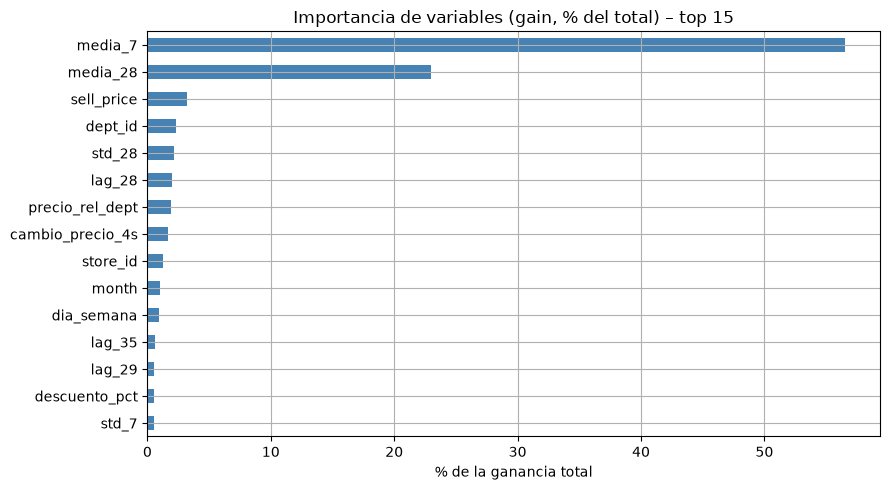

media_7             56.54
media_28            22.97
sell_price           3.17
dept_id              2.34
std_28               2.16
lag_28               1.98
precio_rel_dept      1.93
cambio_precio_4s     1.69
store_id             1.28
month                1.05
dia_semana           0.97
lag_35               0.59
lag_29               0.52
std_7                0.50
descuento_pct        0.50


In [35]:
import matplotlib.pyplot as plt

imp = pd.Series(
    modelo.feature_importance(importance_type="gain"),
    index=modelo.feature_name(),
).sort_values(ascending=False)
imp_pct = (imp / imp.sum() * 100).round(2)

ax = imp_pct.head(15).sort_values().plot(kind="barh", figsize=(9, 5), color="steelblue")
ax.set_title("Importancia de variables (gain, % del total) – top 15")
ax.set_xlabel("% de la ganancia total")
plt.tight_layout()
plt.show()

print(imp_pct.head(15).to_string())

**Resultado:** las dos medias móviles dominan el modelo: `media_7` aporta el 56,5 % de la ganancia total y `media_28` el 23,0 % (79,5 % entre ambas). Les siguen las variables de precio (`sell_price` 3,2 %, `precio_rel_dept` 1,9 %, `cambio_precio_4s` 1,7 %, ≈ 6,8 % en conjunto) y el departamento (2,3 %). Las variables de calendario individuales aportan poco (`dia_semana` 1,0 %, `month` 1,1 %), probablemente porque la estacionalidad semanal ya está implícita en los lags y medias. La importancia indica qué variables usa el modelo, no una relación causal; además, `media_7` y `media_28` están correlacionadas, por lo que el reparto entre ambas es aproximado.

## 4.2 Impacto de los eventos de calendario 
`Влияние календарных событий`

Se compara la venta media de los días con evento frente a los días sin evento, **por tipo de evento**, usando todo el historial (`d_1500 … d_1913`). Es un análisis descriptivo: cada evento aparece solo 1-2 veces en la ventana, y el efecto está mezclado con el día de la semana.

In [36]:
# Venta total diaria (suma de series) y atributos del día
diario = largo.groupby("date", observed=True).agg(
    ventas=("ventas", "sum"),
    tipo=("event_type_1", "first"),
    nombre=("event_name_1", "first"),
    dia_semana=("dia_semana", "first"),
).reset_index()

# Referencia: promedio de los días SIN evento con el mismo día de la semana
base_dow = diario.loc[diario["tipo"] == "Ninguno"].groupby("dia_semana")["ventas"].mean()
diario["esperado"] = diario["dia_semana"].map(base_dow)
diario["efecto_pct"] = (diario["ventas"] / diario["esperado"] - 1) * 100

por_tipo = diario.loc[diario["tipo"] != "Ninguno"].groupby("tipo", observed=True)["efecto_pct"].agg(["mean", "count"]).round(1)
print(por_tipo)

por_evento = (
    diario.loc[diario["tipo"] != "Ninguno"]
    .groupby("nombre", observed=True)["efecto_pct"].mean().round(1).sort_values()
)
print("\nMayores caídas:\n", por_evento.head(5))
print("\nMayores subidas:\n", por_evento.tail(5))

           mean  count
tipo                  
Cultural   -8.8      9
National   -8.8     10
Religious   0.1     10
Sporting   -5.1      3

Mayores caídas:
 nombre
Christmas         -100.0
Thanksgiving       -34.7
Mother's day       -22.8
IndependenceDay    -19.6
NewYear            -18.7
Name: efecto_pct, dtype: float64

Mayores subidas:
 nombre
MartinLutherKingDay    11.7
LentStart              11.9
ColumbusDay            14.6
PresidentsDay          19.3
LaborDay               31.5
Name: efecto_pct, dtype: float64


**Resultado:** respecto a un día normal con el mismo día de la semana, los eventos `Cultural` y `National` reducen las ventas en promedio un 8,8 % y los `Sporting` un 5,1 %. El tipo `Religious` muestra un efecto medio nulo (+0,1 %), pero oculta efectos de signo opuesto (Pesach End −10,6 % y Orthodox Easter −8,3 % frente a Lent Start +11,9 % y Ramadan starts +4,1 %). El mayor impacto es **Christmas (−100 %, tiendas cerradas)**, seguido de Thanksgiving (−34,7 %), Mother's Day (−22,8 %), Independence Day (−19,6 %) y New Year (−18,7 %). El promedio de `National` está dominado por Christmas; sin él sería de aproximadamente +1 %. Aumentan las ventas Labor Day (+31,5 %), Presidents Day (+19,3 %), Columbus Day (+14,6 %) y Martin Luther King Day (+11,7 %), que coinciden con fines de semana largos. *Limitación:* cada evento aparece 1-2 veces en la ventana y el análisis no controla la tendencia estacional; los resultados son indicativos.

In [37]:
pd.set_option("display.max_rows", None)

por_evento_full = (
    diario.loc[diario["tipo"] != "Ninguno"]
    .groupby(["nombre", "tipo"], observed=True)["efecto_pct"]
    .agg(["mean", "count"])
    .round(1)
    .sort_values("mean")
)
print(por_evento_full)

                                mean  count
nombre              tipo                   
Christmas           National  -100.0      1
Thanksgiving        National   -34.7      1
Mother's day        Cultural   -22.8      1
IndependenceDay     National   -19.6      1
NewYear             National   -18.7      1
Father's day        Cultural   -13.4      1
SuperBowl           Sporting   -12.8      1
Pesach End          Religious  -10.6      1
ValentinesDay       Cultural   -10.1      1
OrthodoxEaster      Religious   -8.3      1
StPatricksDay       Cultural    -7.7      2
Easter              Cultural    -7.2      2
NBAFinalsEnd        Sporting    -4.5      1
Chanukah End        Religious   -3.9      1
Cinco De Mayo       Cultural    -2.4      1
VeteransDay         National    -1.3      1
Halloween           Cultural    -0.9      1
Eid al-Fitr         Religious   -0.7      1
EidAlAdha           Religious   -0.4      1
LentWeek2           Religious   -0.3      1
NBAFinalsStart      Sporting    

In [38]:
print(f"Número de árboles: {modelo.num_trees()}")

Número de árboles: 500


In [39]:
modelo_path = Path("..") / "models" / "lgbm_m5_ca.txt"
print(f"Existe: {modelo_path.exists()}")
if modelo_path.exists():
    print(f"Tamaño: {modelo_path.stat().st_size / 1024**2:.1f} MB")

Existe: True
Tamaño: 3.3 MB


## 4.3 Informe ejecutivo y recomendaciones
`Исполнительный отчёт и рекомендации`

### 4.3.1 Resumen de resultados
Se construyó un pipeline de pronóstico de ventas a 28 días por producto y tienda para el estado de California (4 tiendas, 12 196 series, `d_1500 … d_1913`), con validación en los últimos 28 días conocidos (`d_1886 … d_1913`).

| Modelo | RMSE | MAE |
|---|---|---|
| Ingenuo estacional | 2,8315 | 1,3244 |
| Media móvil 28 días (mejor baseline) | 2,2604 | 1,1070 |
| Predicción cero | 3,8650 | 1,4764 |
| **LightGBM** | **2,1613** | 1,1097 |

- LightGBM reduce el RMSE un **4,4 %** frente al mejor baseline; en MAE el resultado es equivalente (−0,2 %).
- La mejora se concentra en `FOODS` (RMSE −5,8 %, 63,7 % de las unidades) y crece con el horizonte: −0,8 % en la semana 1 y −8,4 % en la semana 4.
- El modelo no presenta sesgo sistemático (predicción media 1,4741 frente a venta real 1,4764).
- Las variables más importantes son las medias móviles de 7 y 28 días (79,5 % de la ganancia); los precios aportan ≈ 6,8 %; el calendario individual aporta poco.
- El 57 % de los días-serie tiene venta 0, por lo que el problema es de demanda intermitente y las ganancias posibles son limitadas.

### 4.3.2 Impacto de los eventos de calendario
- **Cierre de tiendas:** Christmas (−100 %).
- **Caídas fuertes:** Thanksgiving (−34,7 %), Mother's Day (−22,8 %), Independence Day (−19,6 %), New Year (−18,7 %), Father's Day (−13,4 %), Super Bowl (−12,8 %).
- **Aumentos:** Labor Day (+31,5 %), Presidents Day (+19,3 %), Columbus Day (+14,6 %), Martin Luther King Day (+11,7 %), todos fines de semana largos.
- Los días SNAP (días 1-10 de cada mes) venden un 5,8 % más, pero el efecto no se puede separar del efecto "inicio de mes".
- Sábado y domingo venden un 40-45 % más que martes-jueves.
- Cada evento aparece solo 1-2 veces en la ventana: los porcentajes son indicativos, no estadísticamente concluyentes.

### 4.3.3 Recomendaciones para la cadena de suministro
1. **Usar el modelo como base de planificación en horizontes de 2-4 semanas**, donde su ventaja sobre la media móvil es mayor (RMSE −5 % a −8 %). Para la primera semana, la media móvil reciente es una alternativa igual de válida.
2. **Concentrar el esfuerzo en `FOODS`:** es el 63,7 % de las unidades y donde el modelo mejora más.
3. **Calendario operativo de eventos:** ajustar los pedidos a la baja en Thanksgiving, Día de la Madre, Día de la Independencia y Año Nuevo, planificar cero reposición el 25 de diciembre y reforzar el inventario antes de los fines de semana largos (Labor Day, Presidents Day, Columbus Day).
4. **Reforzar el stock en fines de semana y en los primeros 10 días del mes**, cuando la demanda es mayor.
5. **Sin sesgo sistemático:** el modelo no tiende a generar quiebres ni excesos de stock en promedio, pero el costo asimétrico (faltante vs. exceso) no fue evaluado; antes de fijar niveles de inventario de seguridad conviene medirlo con datos de costo reales.
6. **Series de baja rotación:** para las series con más de 80 % de días en cero (21,4 %), el valor del modelo es bajo; conviene gestionarlas con reglas simples de reposición.

*Nota:* las recomendaciones 3 y 4 se basan en patrones descriptivos con pocas observaciones por evento y deben validarse con más historia.

### 4.3.4 Limitaciones y próximos pasos
- No se calculó WRMSSE (restricción de tiempo); se reportan RMSE y MAE, que no ponderan por valor monetario.
- Un único corte de validación; solo CA y 414 días de historia; sin búsqueda de hiperparámetros.
- **Próximos pasos:** (1) estrategia recursiva o combinación con la media reciente para los primeros días del horizonte; (2) expanding window con varios cortes; (3) calcular WRMSSE; (4) ampliar a TX y WI y a más historia para separar tendencia y estacionalidad anual; (5) probar un objetivo orientado a la mediana o cuantiles para mejorar el MAE.